<a href="https://colab.research.google.com/github/3b232078/2026_DL_hws/blob/main/hw3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 深度學習 作業3

## 載入套件

In [52]:
import numpy as np
import matplotlib.pyplot as plt

In [53]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import InputLayer

## 資料預處理

In [54]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

In [55]:
# 顯示資料形狀

print("x_train:", x_train.shape)
print("x_test:", x_test.shape)

x_train: (60000, 28, 28)
x_test: (10000, 28, 28)


### 正規化和reshape

In [56]:
x_train_normalize = x_train.reshape(60000, 784).astype('float32') / 255
x_test_normalize = x_test.reshape(10000, 784).astype('float32') / 255

### one-hot encoding

In [57]:
y_train_oh = to_categorical(y_train, 10)
y_test_oh = to_categorical(y_test, 10)

### 三張訓練圖片與真實標籤

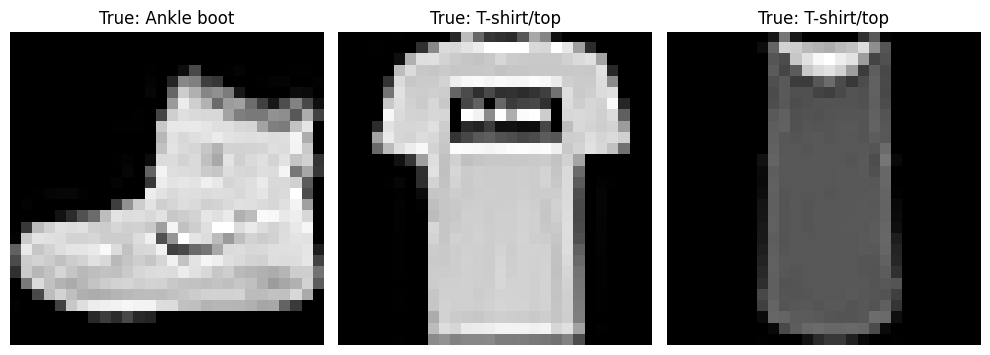

In [58]:
labels = ["T-shirt/top", "Trouser", "Pullover",
      "Dress", "Coat", "Sandal",
      "Shirt", "Sneaker", "Bag",
      "Ankle boot"]

plt.figure(figsize=(10, 4))

for i in range(3):
    plt.subplot(1, 3, i + 1)

    plt.imshow(x_train[i].reshape(28, 28), cmap="gray")
    plt.title("True: " + labels[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 建立神經網路模型

In [59]:
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout

In [60]:
model = Sequential()

# 輸入層
model.add(InputLayer(shape=(784,)))
model.add(Dropout(0.2))

# 第一隱藏層
model.add(Dense(512, kernel_initializer='he_normal', activation='relu'))
model.add(Dropout(0.4))

# 第二隱藏層
model.add(Dense(256, kernel_initializer='he_normal', activation='relu'))
model.add(Dropout(0.2))

# 第三隱藏層
model.add(Dense(128, kernel_initializer='he_normal', activation='relu'))
model.add(Dropout(0.2))

# 輸出層
model.add(Dense(units=10, kernel_initializer='he_normal', activation='softmax'))

In [61]:
# 顯示模型架構
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dropout_12 (Dropout)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 567,434 (2.16 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

神經網路模型參數計算：
* 第一隱藏層：784*512+512=401,920
* 第二隱藏層：512*256+256=131,328
* 第三隱藏層：256*256+128=32,896
* 輸出層：128*10+10=1,290
* 總參數數量：401,920+131,328+32,896+1,290=567,434

## 訓練神經網路模型

In [62]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

In [63]:
train_history = model.fit(
    x_train_normalize, y_train_oh,
    validation_split=0.2, # 切20%驗證
    epochs=30,
    batch_size=200,
    verbose=2)

Epoch 1/30
240/240 - 9s - 36ms/step - accuracy: 0.7168 - loss: 0.7744 - val_accuracy: 0.8293 - val_loss: 0.4742
Epoch 2/30
240/240 - 5s - 22ms/step - accuracy: 0.8103 - loss: 0.5223 - val_accuracy: 0.8448 - val_loss: 0.4185
Epoch 3/30
240/240 - 7s - 31ms/step - accuracy: 0.8265 - loss: 0.4705 - val_accuracy: 0.8568 - val_loss: 0.3843
Epoch 4/30
240/240 - 5s - 22ms/step - accuracy: 0.8374 - loss: 0.4407 - val_accuracy: 0.8664 - val_loss: 0.3688
Epoch 5/30
240/240 - 11s - 47ms/step - accuracy: 0.8450 - loss: 0.4237 - val_accuracy: 0.8658 - val_loss: 0.3575
Epoch 6/30
240/240 - 5s - 23ms/step - accuracy: 0.8495 - loss: 0.4079 - val_accuracy: 0.8700 - val_loss: 0.3576
Epoch 7/30
240/240 - 7s - 29ms/step - accuracy: 0.8556 - loss: 0.3918 - val_accuracy: 0.8667 - val_loss: 0.3507
Epoch 8/30
240/240 - 9s - 39ms/step - accuracy: 0.8584 - loss: 0.3815 - val_accuracy: 0.8777 - val_loss: 0.3353
Epoch 9/30
240/240 - 6s - 25ms/step - accuracy: 0.8595 - loss: 0.3785 - val_accuracy: 0.8780 - val_loss

##　折線圖顯示訓練過程

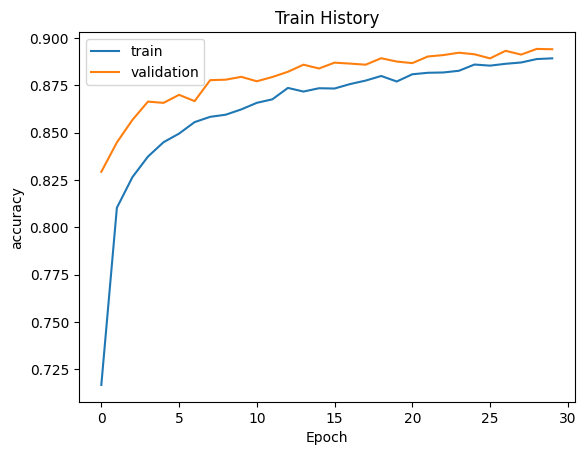

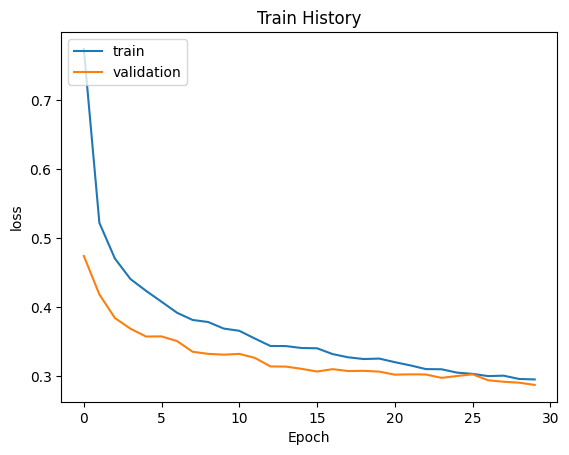

In [64]:
def show_train_history(train_history, train, validation):
  plt.plot(train_history.history[train])
  plt.plot(train_history.history[validation])
  plt.title('Train History')
  plt.ylabel(train)
  plt.xlabel('Epoch')
  plt.legend(['train', 'validation'], loc='upper left')
  plt.show()

#　準確率(accuracy)
show_train_history(train_history, 'accuracy', 'val_accuracy')

#　損失誤差(loss)
show_train_history(train_history, 'loss', 'val_loss')

## 評估模型準確率

In [65]:
scores = model.evaluate(x_test_normalize, y_test_oh)
print(f"accuracy = {scores[1]}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8888 - loss: 0.3097
accuracy = 0.8888000249862671


## 預測

In [66]:
predictions = model.predict(x_test_normalize)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [67]:
predicted_classes = np.argmax(predictions, axis=1)

In [68]:
predicted_classes

array([9, 2, 1, ..., 8, 1, 5])

### 顯示圖片與標籤名稱

In [69]:
import matplotlib.pyplot as plt

def plot_images_labels_prediction(images, true_labels, pred_labels, label_names, idx=0, num=10):
  plt.figure(figsize=(6, 7))
  if num > 25: num = 25
  for i in range(num):
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[idx + i], cmap='gray')

    true_name = label_names[true_labels[idx + i]]
    pred_name = label_names[pred_labels[idx + i]]

    plt.title(f'True: {true_name}\nPred: {pred_name}', fontsize=10)
    plt.axis('off')

  plt.tight_layout()
  plt.show()

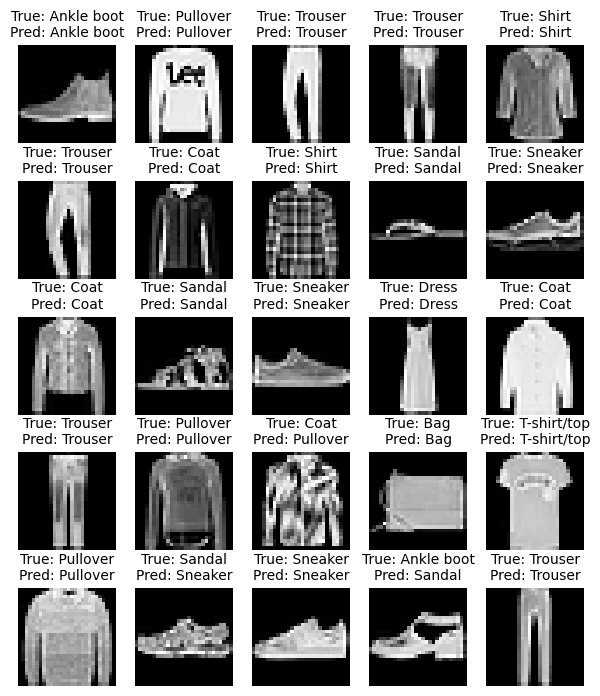

In [70]:
plot_images_labels_prediction(x_test, y_test, predicted_classes, labels, idx=0, num=25)

## 混淆矩陣 (Confusion Matrix)

In [73]:
import pandas as pd

pd.crosstab(y_test, predicted_classes, rownames=['label'], colnames=['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,857,2,13,12,4,0,108,0,4,0
1,4,975,2,15,2,0,1,0,1,0
2,18,0,804,10,105,0,61,0,2,0
3,20,7,9,903,33,0,25,0,3,0
4,1,0,102,31,824,0,40,0,2,0
5,0,0,0,0,0,952,0,34,2,12
6,121,0,94,29,85,0,662,0,9,0
7,0,0,0,0,0,2,0,982,0,16
8,3,0,4,5,6,1,2,4,975,0


## 儲存完整模型

In [74]:
from google.colab import drive

drive.mount('/content/drive')

%cd '/content/drive/My Drive/Colab Notebooks'

model.save('hw3.keras')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/Colab Notebooks
